# Deep Generative Models
## Seminar 5 — StyleGAN

**MIPT / YSDA · Autumn 2026 · 15.10.2026**

**Credits**: 

The code is based on [github_1](https://github.com/davidsosa/GANs) and [github_2](https://github.com/rosinality/style-based-gan-pytorch)

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

# Works when Jupyter starts in the repository root or this notebook directory.
SEMINAR_DIR = next(
    (p for p in (Path.cwd() / 'seminars' / 'seminar5', Path.cwd())
     if (p / 'seminar5_stylegan.ipynb').is_file()),
    Path.cwd(),
)


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributions as TD
from torchvision.utils import make_grid
import pickle
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


if torch.cuda.is_available():
    DEVICE = 'cuda'
    GPU_DEVICE = 0
    FULL_DEVICE = 'cuda:{}'.format(GPU_DEVICE)
    torch.cuda.set_device(GPU_DEVICE)
else:
    DEVICE='cpu'
    FULL_DEVICE = 'cpu'
# DEVICE='cpu'

def reset_seed():
    OUTPUT_SEED = 0xBADBEEF
    #OUTPUT_SEED = 42
    torch.manual_seed(OUTPUT_SEED)
    np.random.seed(OUTPUT_SEED)

reset_seed()

In [3]:
from dgm_utils import show_samples, visualize_images, load_dataset

In [4]:
def show_tensor_images(image_tensor, num_images=16, size=(3, 64, 64), nrow=3):
    '''
    Function for visualizing images: Given a tensor of images, number of images,
    size per image, and images per row, plots and prints the images in an uniform grid.
    '''
    image_tensor = (image_tensor + 1) / 2
    image_unflat = image_tensor.detach().cpu().clamp_(0, 1)
    image_grid = make_grid(image_unflat[:num_images], nrow=nrow, padding=0)
    plt.imshow(image_grid.permute(1, 2, 0).squeeze())
    plt.axis('off')
    plt.show()

## 1. Mapping Network

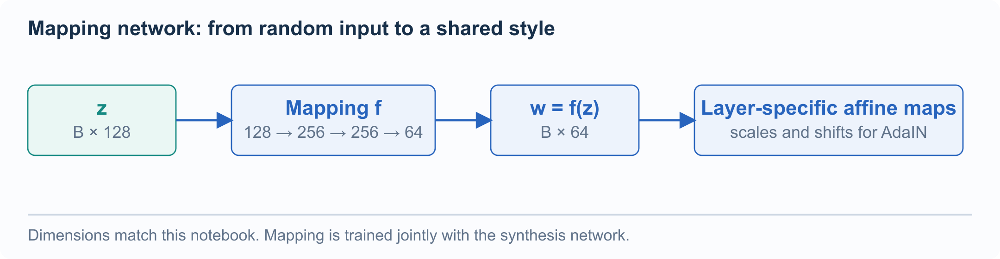

$$z\sim\mathcal N(0,I),\qquad w=f_\theta(z).$$

A learned mapping separates the simple sampling distribution in $Z$ from the style representation in $W$. In this teaching model, the hidden layers use ReLU and the final linear layer produces a 64-dimensional style.

> **Takeaway.** We still sample in $Z$. The synthesis network is controlled through $W$, using its own learned affine maps at each AdaIN layer.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [5]:
class MappingLayers(nn.Module):
    '''
    Mapping Layers Class
    Values:
        z_dim: the dimension of the noise vector, a scalar
        hidden_dim: the inner dimension, a scalar
        w_dim: the dimension of the intermediate noise vector, a scalar
    '''
 
    def __init__(self, z_dim, hidden_dim, w_dim):
        super().__init__()
        self.mapping = nn.Sequential(
            # A neural network which takes in tensors of 
            # shape (n_samples, z_dim) and outputs (n_samples, w_dim)
            # with a hidden layer with hidden_dim neurons
            nn.Linear(z_dim,hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim,hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, w_dim)
        )

    def forward(self, noise):
        '''
        Function for completing a forward pass of MappingLayers: 
        Given an initial noise tensor, returns the intermediate noise tensor.
        Parameters:
            noise: a noise tensor with dimensions (n_samples, z_dim)
        '''
        return self.mapping(noise)

## 2. Truncation trick

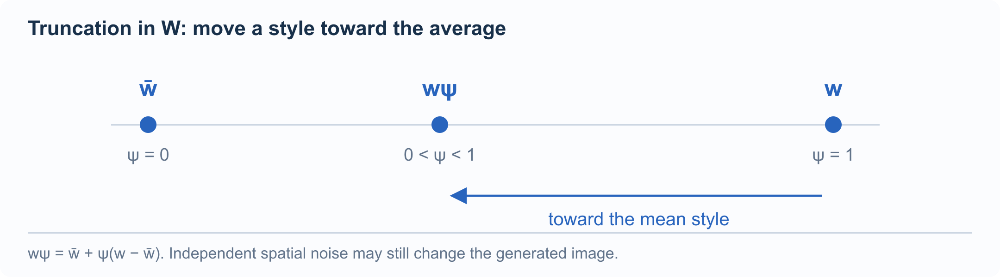

The next cell contains **two different operations**:

- `get_truncated_noise`: sample each coordinate of $z$ from a truncated normal distribution.
- `scale_w`: move the mapped style toward an estimated mean $\bar w$.

$$w_\psi=\bar w+\psi(w-\bar w)=(1-\psi)\bar w+\psi w.$$

At $\psi=1$ we keep the original style; at $\psi=0$ every sample uses $\bar w$. Values between 0 and 1 reduce style variation. Spatial noise can still vary.

> **Takeaway.** Truncation in $Z$ and truncation toward $\bar w$ in $W$ are not interchangeable. Later demonstrations use `scale_w`.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [6]:
from scipy.stats import truncnorm

def get_truncated_noise(n_samples, z_dim, truncation):
    '''
    Function for creating truncated noise vectors: Given the dimensions (n_samples, z_dim)
    and truncation value, creates a tensor of that shape filled with random
    numbers from the truncated normal distribution.
    Parameters:
        n_samples: the number of samples to generate, a scalar
        z_dim: the dimension of the noise vector, a scalar
        truncation: the truncation value, a non-negative scalar
    '''
    truncated_noise = truncnorm.rvs(-1*truncation, truncation, size=(n_samples, z_dim))
    return torch.Tensor(truncated_noise)

def scale_w(w, w_mean=None, w_weight=None):
    if w_mean is not None:
        w = w_mean + w_weight * (w - w_mean)
    return w

## 3. Injection Noise

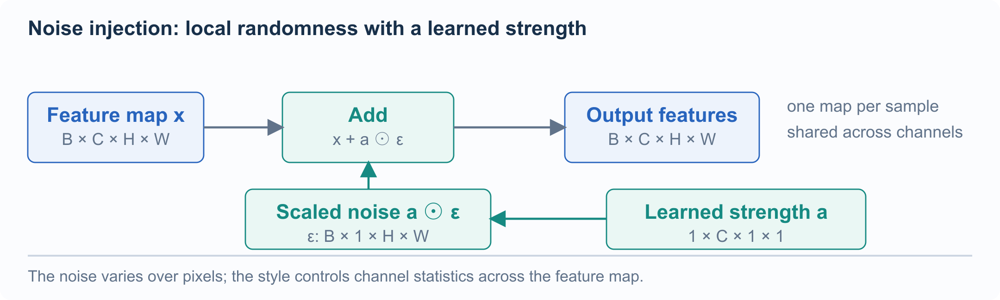

For sample $b$, channel $c$ and pixel $(h,w)$,

$$y_{bchw}=x_{bchw}+a_c\,\epsilon_{bhw},\qquad\epsilon_{bhw}\sim\mathcal N(0,1).$$

The sampled noise is independent over spatial locations and samples. A learned scalar $a_c$ determines its strength in each channel. A new noise map is sampled at each call to the layer.

> **Takeaway.** Keeping the style fixed does not fix every pixel. Spatial noise gives the synthesis network an additional source of local variation.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [7]:
class InjectNoise(nn.Module):
    '''
    Inject Noise Class
    Values:
        channels: the number of channels the image has, a scalar
    '''
    def __init__(self, channels):

        super().__init__()
        self.weight = nn.Parameter( # You use nn.Parameter so that these weights can be optimized
            # Initiate the weights for the channels from a random normal distribution
            torch.randn(channels)[None, :, None, None] #torch.randn((1,channels,1,1))
        )

    def forward(self, image):
        '''
        Function for completing a forward pass of InjectNoise: Given an image, 
        returns the image with random noise added.
        Parameters:
            image: the feature map of shape (n_samples, channels, width, height)
        '''
        # Set the appropriate shape for the noise!

        noise_shape = (image.shape[0], 1, image.shape[2], image.shape[3])

        noise = torch.randn(noise_shape, device=image.device) # Creates the random noise
        return image + self.weight * noise # Applies to image after multiplying by the weight for each channel

## 4. Adaptive Normalization

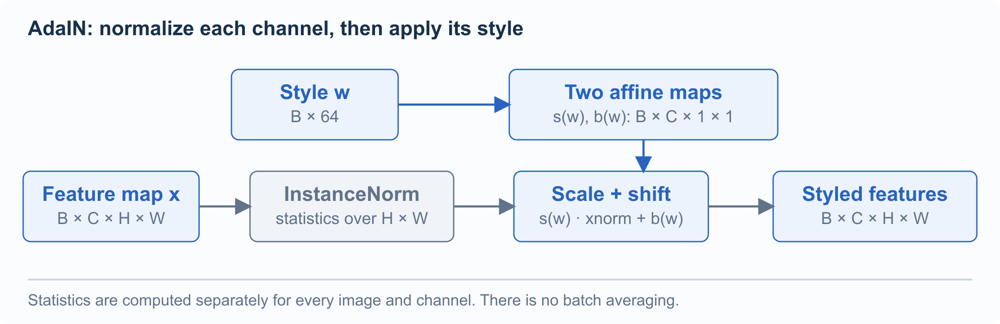

### Derivation: normalize, then set new channel statistics

For each sample $b$ and channel $c$, compute statistics over its $H\times W$ spatial positions:

$$\mu_{bc}=\frac1{HW}\sum_{h,w}x_{bchw},\qquad v_{bc}=\frac1{HW}\sum_{h,w}(x_{bchw}-\mu_{bc})^2.$$

Normalize, then apply the style-dependent scale and shift:

$$\hat x_{bchw}=\frac{x_{bchw}-\mu_{bc}}{\sqrt{v_{bc}+\varepsilon}},\qquad
 y_{bchw}=s_c(w_b)\hat x_{bchw}+b_c(w_b).$$

In code, the affine outputs change shape from $(B,C)$ to $(B,C,1,1)$ so they broadcast over the image. The output mean is $b_c(w_b)$ and its variance is $s_c(w_b)^2v_{bc}/(v_{bc}+\varepsilon)$, approximately $s_c(w_b)^2$ when the normalization epsilon is negligible.

> **Takeaway.** AdaIN first removes the current channel statistics and then replaces them with learned, style-dependent statistics. It does not average across the batch.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [8]:
# Adaptive Instance Norm
class AdaIN(nn.Module):
    '''
    AdaIN Class
    Values:
        channels: the number of channels the image has, a scalar
        w_dim: the dimension of the intermediate noise vector, a scalar
    '''

    def __init__(self, channels, w_dim):
        super().__init__()

        # Normalize the input per-channels
        self.instance_norm = nn.InstanceNorm2d(channels)

        # You want to map w to a set of style weights per channel.
        # Replace the Nones with the correct dimensions - keep in mind that 
        # both linear maps transform a w vector into style weights 
        # corresponding to the number of image channels.
        self.style_scale_transform = nn.Linear(w_dim, channels)
        self.style_shift_transform = nn.Linear(w_dim, channels)

    def forward(self, image, w):
        '''
        Function for completing a forward pass of AdaIN: Given an image and intermediate noise vector w, 
        returns the normalized image that has been scaled and shifted by the style.
        Parameters:
            image: the feature map of shape (n_samples, channels, width, height)
            w: the intermediate noise vector w
        '''
        normalized_image = self.instance_norm(image) # (bs, c, w, h)
        style_scale = self.style_scale_transform(w)[:, :, None, None]
        style_shift = self.style_shift_transform(w)[:, :, None, None]

        # Calculate the transformed image
        transformed_image = style_scale * normalized_image + style_shift
        return transformed_image

## 5. Progressive GAN

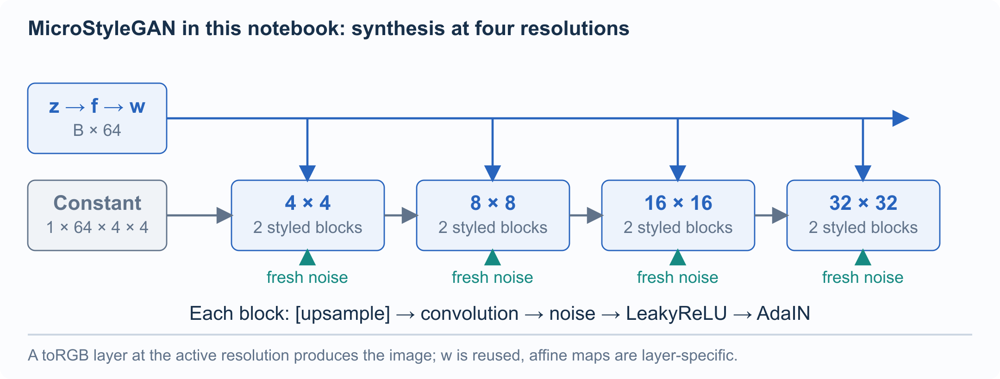

The initial tensor is a learned parameter shared across samples. Different styles and noise maps produce different images from that common starting point.

Each resolution uses two styled blocks. The first block upsamples when moving to a higher resolution; each block follows the exact order shown above. A `to_rgb` layer maps features to RGB and `Tanh` gives values in $[-1,1]$.

> **Takeaway.** Separate the three ingredients: a shared learned constant, a per-sample style, and per-layer spatial noise. The diagram describes the small CIFAR10 model below, not the later pretrained StyleGAN2.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [9]:
class MicroStyleGANGeneratorBlock(nn.Module):
    '''
    Micro StyleGAN Generator Block Class
    Values:
        in_chan: the number of channels in the input, a scalar
        out_chan: the number of channels wanted in the output, a scalar
        w_dim: the dimension of the intermediate noise vector, a scalar
        kernel_size: the size of the convolving kernel
        starting_size: the size of the starting image
    '''

    def __init__(
        self, 
        in_chan, 
        out_chan, 
        w_dim, 
        kernel_size, 
        starting_size, 
        use_upsample=True):

        super().__init__()
        self.use_upsample = use_upsample

        if self.use_upsample:
            self.upsample = nn.Upsample(starting_size, mode='bilinear')
        self.conv = nn.Conv2d(in_chan, out_chan, kernel_size, padding=kernel_size // 2) # Padding is used to maintain the image size
        self.inject_noise = InjectNoise(out_chan)
        self.adain = AdaIN(out_chan, w_dim)
        self.activation = nn.LeakyReLU(0.2)

    def forward(self, x, w):
        '''
        Function for completing a forward pass of MicroStyleGANGeneratorBlock: Given an x and w, 
        computes a StyleGAN generator block.
        Parameters:
            x: the input into the generator, feature map of shape (n_samples, channels, width, height)
            w: the intermediate noise vector
        '''
        if self.use_upsample:
            x = self.upsample(x)
        x = self.conv(x)
        x = self.inject_noise(x)
        x = self.activation(x)
        x = self.adain(x, w)
        return x

class StyledSequential(nn.Sequential):

    def forward(self, x, w):
        for module in self._modules.values():
            x = module(x, w)
        return x

In [10]:
class MicroStyleGANGenerator(nn.Module):
    '''
    Micro StyleGAN Generator Class
    Values:
        z_dim: the dimension of the noise vector, a scalar
        map_hidden_dim: the mapping inner dimension, a scalar
        w_dim: the dimension of the intermediate noise vector, a scalar
        in_chan: the dimension of the constant input, usually w_dim, a scalar
        out_chan: the number of channels wanted in the output, a scalar
        kernel_size: the size of the convolving kernel
        hidden_chan: the inner dimension, a scalar
    '''

    def _sample_prior(self, n):
        x = self.prior.sample((n, self.z_dim))
        return x

    def __init__(self, 
                 z_dim, # z dimensionality
                 map_hidden_dim, # mapping network parameter
                 w_dim, # style vector dimensionality
                 in_chan, # number of channels in input trainable tensor
                 out_chan, # images dimensionality
                 kernel_size, 
                 hidden_chan, device='cpu'):
        super().__init__()
        self.prior = TD.Normal(torch.tensor(0.0).to(device), torch.tensor(1.0).to(device))
        self.z_dim = z_dim
        self.map = MappingLayers(z_dim, map_hidden_dim, w_dim)
        # Typically this constant is initiated to all ones, but you will initiate to a
        # Gaussian to better visualize the network's effect
        self.starting_constant = nn.Parameter(torch.randn(1, in_chan, 4, 4))

        self.progression = nn.ModuleList(
            [
                StyledSequential(*[
                    MicroStyleGANGeneratorBlock(in_chan, hidden_chan, w_dim, kernel_size, 4, use_upsample=False),
                    MicroStyleGANGeneratorBlock(hidden_chan, hidden_chan, w_dim, kernel_size, 4, use_upsample=False)]),
                StyledSequential(*[
                    MicroStyleGANGeneratorBlock(hidden_chan, hidden_chan, w_dim, kernel_size, 8, use_upsample=True),
                    MicroStyleGANGeneratorBlock(hidden_chan, hidden_chan, w_dim, kernel_size, 8, use_upsample=False)]),
                StyledSequential(*[
                    MicroStyleGANGeneratorBlock(hidden_chan, hidden_chan, w_dim, kernel_size, 16, use_upsample=True),
                    MicroStyleGANGeneratorBlock(hidden_chan, hidden_chan, w_dim, kernel_size, 16, use_upsample=False)]),
                StyledSequential(*[
                    MicroStyleGANGeneratorBlock(hidden_chan, hidden_chan, w_dim, kernel_size, 32, use_upsample=True),
                    MicroStyleGANGeneratorBlock(hidden_chan, hidden_chan, w_dim, kernel_size, 32, use_upsample=False)])
            ]
        )

        self.to_rgb = nn.ModuleList(
            [
                nn.Sequential(*[nn.Conv2d(hidden_chan, out_chan, kernel_size=1), nn.Tanh()]), # out_chan = 3
                nn.Sequential(*[nn.Conv2d(hidden_chan, out_chan, kernel_size=1), nn.Tanh()]),
                nn.Sequential(*[nn.Conv2d(hidden_chan, out_chan, kernel_size=1), nn.Tanh()]),
                nn.Sequential(*[nn.Conv2d(hidden_chan, out_chan, kernel_size=1), nn.Tanh()])
            ]
        )

    def forward(self, noise, step=0, alpha=-1, w_mean=None, w_weight=None):
        '''
        Function for completing a forward pass of MicroStyleGANGenerator: Given noise, 
        computes a StyleGAN iteration.
        Parameters:
            noise: a noise tensor with dimensions (n_samples, z_dim)
            return_intermediate: a boolean, true to return the images as well (for testing) and false otherwise
        '''
        x = self.starting_constant
        w = self.map(noise)
        w = scale_w(w, w_mean, w_weight)

        for i, (block, to_rgb) in enumerate(zip(self.progression, self.to_rgb)):

            if i > 0 and step > 0:
                x_prev = x

            x = block(x, w)

            if i == step:
                x = to_rgb(x)

                if i > 0 and 0 <= alpha < 1:
                    skip_rgb = self.to_rgb[i - 1](x_prev)
                    skip_rgb = F.interpolate(skip_rgb, scale_factor=2, mode='bilinear')
                    x = (1 - alpha) * skip_rgb + alpha * x
                break

        return x

    def sample(self, n, step=0, alpha=-1, w_mean=None, w_weight=None):
        with torch.no_grad():
            return self.rsample(n, step, alpha, w_mean, w_weight)

    def rsample(self, n, step=0, alpha=-1, w_mean=None, w_weight=None):
        noise = self._sample_prior(n)
        return self.forward(noise, step, alpha, w_mean, w_weight)

## 6. Discriminator

In [11]:
class ConvBlock(nn.Module):

    def __init__(
        self,
        in_channel,
        out_channel,
        kernel_size,
        downsample=False,
    ):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channel, out_channel, kernel_size, padding=kernel_size//2),
            nn.LeakyReLU(0.2),
        )

        if downsample:
            self.conv2 = nn.Sequential(
                nn.Conv2d(out_channel, out_channel, kernel_size, padding=kernel_size//2),
                nn.AvgPool2d(2),
                nn.LeakyReLU(0.2),
            )

        else:
            self.conv2 = nn.Sequential(
                nn.Conv2d(out_channel, out_channel, kernel_size, padding=kernel_size//2),
                nn.LeakyReLU(0.2),
            )

    def forward(self, input):
        out = self.conv1(input)
        out = self.conv2(out)

        return out

class Discriminator(nn.Module):

    def __init__(
        self, 
        in_chan,
        out_chan, 
        kernel_size, 
        hidden_chan):

        super().__init__()

        self.progression = nn.ModuleList(
            [
                ConvBlock(hidden_chan, hidden_chan, kernel_size, downsample=True), # 16
                ConvBlock(hidden_chan, hidden_chan, kernel_size, downsample=True), # 8
                ConvBlock(hidden_chan, hidden_chan, kernel_size, downsample=True), # 4
                nn.Sequential(*[
                    nn.Conv2d(hidden_chan, hidden_chan, kernel_size, padding=kernel_size//2),
                    nn.LeakyReLU(0.2),
                    nn.Conv2d(hidden_chan, in_chan, 4, padding=0),
                    nn.LeakyReLU(0.2)])
            ]
        )

        self.from_rgb = nn.ModuleList(
            [
                nn.Conv2d(out_chan, hidden_chan, kernel_size=1),
                nn.Conv2d(out_chan, hidden_chan, kernel_size=1),
                nn.Conv2d(out_chan, hidden_chan, kernel_size=1),
                nn.Conv2d(out_chan, hidden_chan, kernel_size=1)
            ]
        )

        self.n_layer = len(self.progression)

        self.linear = nn.Linear(in_chan, 1)

    def forward(self, input, step=0, alpha=-1):
        out = self.from_rgb[self.n_layer - step - 1](input)
        out = self.progression[self.n_layer - step - 1](out)

        if step > 0 and  0 <= alpha < 1:
            skip_rgb = F.avg_pool2d(input, 2)
            skip_rgb = self.from_rgb[self.n_layer - step](skip_rgb)
            out = (1 - alpha) * skip_rgb + alpha * out

        for i in range(step - 1, -1, -1):
            index = self.n_layer - i - 1
            out = self.progression[index](out)

        out = out.squeeze(2).squeeze(2)
        # print(input.size(), out.size(), step)
        out = self.linear(out)

        return out

## 7. Dataset

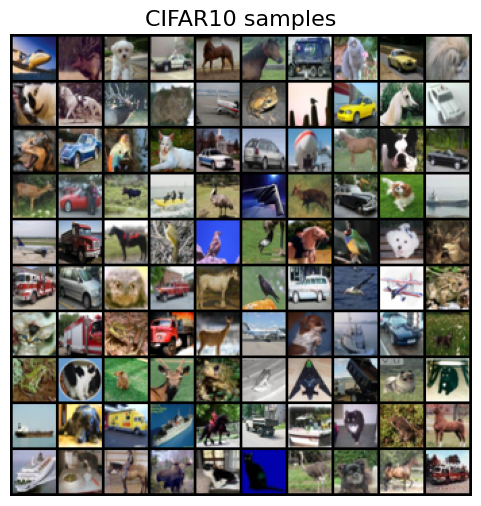

In [12]:
train_data, test_data = load_dataset('cifar10', binarize=False)
visualize_images(train_data, 'CIFAR10 samples')

In [13]:
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import skimage.measure

class MultiResCIFAR10Dataset(Dataset):
    res2avgpoolops = {
        32: 0,
        16: 1,
        8: 2,
        4: 3,
        2: 4
    }

    @property
    def resolution(self):
        return self._resolution

    @resolution.setter
    def resolution(self, val):
        assert val in [2, 4, 8, 16, 32]
        self._resolution = val
        self._avgpoolops = self.res2avgpoolops[val]
        if val in self.data.keys():
            return
        self.data[val] = np.asarray([
            self.np_avgpool2(self.transform(self.init_data[i]), self._avgpoolops) for i in range(len(self.init_data))])

    def np_avgpool2(self, x, num_apply):
        for _ in range(num_apply):
            x = skimage.measure.block_reduce(x, (1, 2, 2), np.mean)
        return x

    def __init__(
        self, 
        data,
        resolution=32,
        transform=lambda x: x,
    ):
        super().__init__()
        self.init_data = data
        self.data = {}
        self.transform = transform
        self.resolution = resolution
        self.transform = transform

    def __len__(self):
        return len(self.init_data)

    def __getitem__(self, index):
        return self.data[self.resolution][index]

In [14]:
def im2rawim(x):
    return (x - 0.5)/0.5

def rawim2im(x):
    return x/2. + 0.5

In [15]:
train_dataset = MultiResCIFAR10Dataset(train_data, transform = im2rawim, resolution=32)

In [16]:
train_dataset.data[32].shape

(50000, 3, 32, 32)

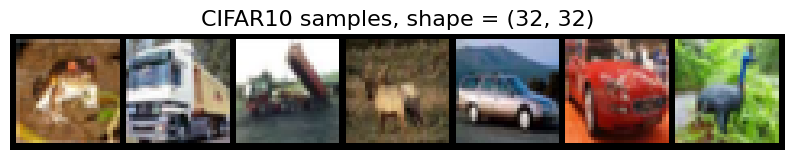

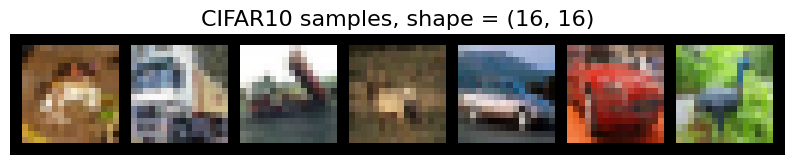

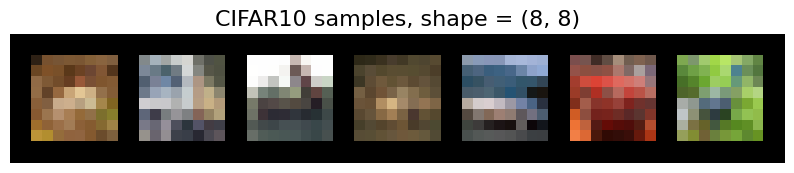

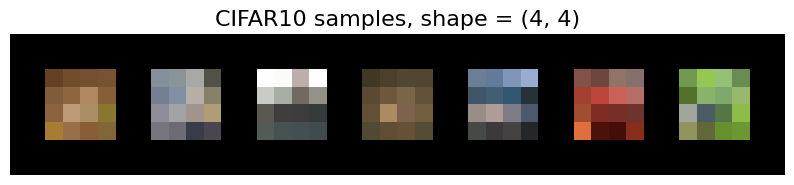

In [17]:
resolutions = [32, 16, 8, 4]
for res in resolutions:
    train_dataset.resolution = res
    dl = DataLoader(train_dataset, batch_size=7, shuffle=False)
    batch = next(iter(dl)).numpy() * 0.5 + 0.5
    show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(res), figsize=(10, 5), nrow=7)

## 8. Basic Training infrastructure

### Non-saturating logistic loss with R1 regularization

Here the network called `critic` returns a **logit** $a(x)$ for a logistic GAN. It is not a Wasserstein critic.

From $D=\sigma(a)$,

$$-\log D=\operatorname{softplus}(-a),\qquad-\log(1-D)=\operatorname{softplus}(a).$$

Therefore the implementation minimizes

$$\begin{aligned}
\mathcal L_D&=\mathbb E_x\operatorname{softplus}(-a(x))+\mathbb E_z\operatorname{softplus}(a(G(z)))+\lambda\mathbb E_x\|\nabla_x a(x)\|_2^2,\\
\mathcal L_G&=\mathbb E_z\operatorname{softplus}(-a(G(z))).
\end{aligned}$$

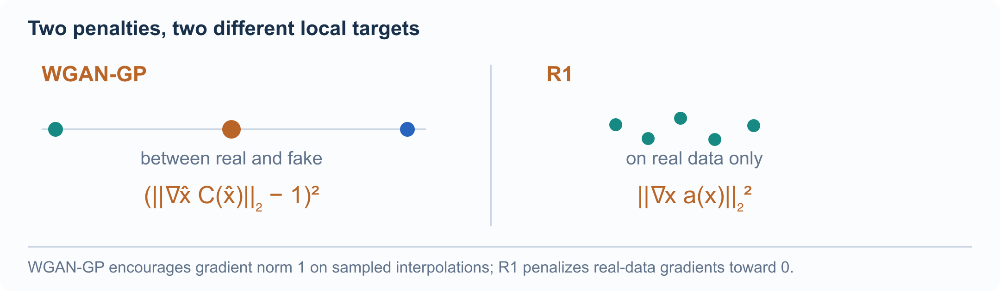

The code uses $\lambda=\texttt{gp\_weight}$; in the common paper convention, the coefficient is $\gamma/2$. `create_graph=True` is needed to train the discriminator using the input-gradient penalty.

> **Takeaway.** R1 and WGAN-GP act at different locations and have different target gradient norms. In this class, `sample()` disables gradients and `rsample()` preserves them; the generator update therefore uses `rsample()`.

<small>Source: [Mescheder et al., Which Training Methods for GANs do actually Converge? (2018)](https://arxiv.org/abs/1801.04406)</small>

In [18]:
from collections import defaultdict

def get_defaultdictlist():
    return defaultdict(list)

class ImagesManager:

    def __init__(self):
        self.stats = defaultdict(get_defaultdictlist)

    def add(self, epoch, images):
        assert isinstance(images, np.ndarray)
        assert len(images.shape) == 4 # bs, c, h, w
        res = images.shape[-1]
        self.stats[res][epoch].append(images)

    def get_resolutions(self):
        return list(self.stats.keys())

    def get_epochs(self, res):
        return sorted(self.stats[res].keys())

    def get_images(self, res, epoch):
        return self.stats[res][epoch]

In [19]:
import torch.autograd as autograd

def computePotGrad(input, output, create_graph=True, retain_graph=True):
    '''
    :Parameters:
    input : tensor (bs, *shape)
    output: tensor (bs, 1) , NN(input)
    :Returns:
    gradient of output w.r.t. input (in batch manner), shape (bs, *shape)
    '''
    grad = autograd.grad(
        outputs=output, 
        inputs=input,
        grad_outputs=torch.ones_like(output),
        create_graph=create_graph,
        retain_graph=retain_graph,
    ) # (bs, *shape) 
    return grad[0]

class StatsManager:

    @staticmethod
    def traverse(o, tree_types=(list, tuple, np.ndarray)):
        if isinstance(o, tree_types):
            for value in o:
                for subvalue in StatsManager.traverse(value, tree_types):
                    yield subvalue
        else:
            yield o

    def __init__(self, *names):
        self.stats = {}
        self.names = list(names)
        for name in names:
            self.stats[name] = []
    
    def add_stat_names(self, *names):
        self.names = self.names + list(names)
        for name in names:
            if name in self.stats.keys():
                raise Exception(
                    "name '{}' has already been presented!".format(name))
            self.stats[name] = []

    def add_all(self, *vals):
        if len(vals) == 1:
            for name in self.names:
                if vals[0] is not None:
                    self.add(name, vals[0])
            return
        if len(vals) == len(self.names):
            for name, val in zip(self.names, vals):
                if val is not None:
                    self.add(name, val)
            return
        raise Exception('stats update is ambiguous')

    def add(self, name, val):
        self.stats[name][-1] += val
    
    def upd_all(self, *vals):
        if len(vals) == 1:
            for name in self.names:
                if vals[0] is not None:
                    self.upd(name, vals[0])
            return
        if len(vals) == len(self.names):
            for name, val in zip(self.names, vals):
                if val is not None:
                    self.upd(name, val)
            return 
        raise Exception('stats update is ambiguous')
    
    def upd(self, name, val):
        self.stats[name].append(val)
    
    def get(self, name):
        return self.stats[name]
    
    def draw(self, axs, names=None):
        axs_list = list(self.traverse(axs))
        if names is None:
            names = self.names
        for i, name in enumerate(names):
            axs_list[i].plot(self.get(name))
            axs_list[i].set_title(name)
    
    def reset(self):
        for name in self.stats.keys():
            self.stats[name] = []
from IPython.display import clear_output

def train_GAN_R1(
    generator, # generator model
    critic, # critic model
    step, # number of progressive steps (defines the resolution under consideration)
    alpha_sheduler, # sheduler of interventions
    train_loader, # loader of the train data
    critic_steps, # number of critic steps per one generator steps
    batch_size,
    n_epochs,
    gen_lr, 
    critic_lr,
    SM, # stats manager to store losses
    IM, # images manager to store images
    start_epoch = 0,
    gp_weight=10, # coefficient of R1 gradient penalty
    use_cuda=False,
    visualize_steps=10,
    save_steps=200
):

    critic.train()
    generator.train()

    gen_optimizer = torch.optim.Adam(generator.parameters(), lr=gen_lr, betas=(0., 0.9))
    critic_optimizer = torch.optim.Adam(critic.parameters(), lr=critic_lr, betas=(0., 0.9))

    curr_iter = 0
    d_loss, g_loss = torch.zeros(1), torch.zeros(1)

    for epoch_i in tqdm(range(start_epoch, n_epochs + start_epoch)):
        for batch_i, real_data in enumerate(train_loader):
            curr_iter += 1
            alpha = alpha_sheduler(curr_iter)
            if use_cuda:
                real_data = real_data.cuda()

            ################
            # CRITIC UPDATE

            critic_optimizer.zero_grad()
            real_data.requires_grad_() # for R1 regularizer estimation
            real_scores = critic(real_data, step=step, alpha=alpha)
            real_predict = F.softplus(- real_scores).mean()

            # R1 gradient penalty
            gradients = computePotGrad(real_data, real_scores)
            grad_penalty = (
                gradients.view(gradients.size(0), -1).norm(2, dim=1) ** 2
            ).mean()

            fake_data = generator.sample(real_data.shape[0], step=step, alpha=alpha)
            fake_scores = critic(fake_data, step=step, alpha=alpha)
            fake_predict = F.softplus(fake_scores).mean()

            d_loss = fake_predict + real_predict + gp_weight * grad_penalty

            d_loss.backward()
            critic_optimizer.step()

            SM.upd('D_loss', d_loss.item())
            SM.upd('GP', grad_penalty.item())
            SM.upd('alpha', alpha)

            ###############
            # GENERATOR_UPDATE

            if curr_iter % critic_steps == 0:
                gen_optimizer.zero_grad()
                fake_data = generator.rsample(batch_size, step=step, alpha=alpha)
                fake_scores = critic(fake_data, step=step, alpha=alpha)
                g_loss = F.softplus(-fake_scores).mean()
                g_loss.backward()
                gen_optimizer.step()
                SM.upd('G_loss', g_loss.item())

        SM.upd('step', step)

        #################
        # statistics collection
        # and visualization

        if visualize_steps and epoch_i % visualize_steps == 0:
            clear_output(wait=True)
            print('Epoch {}'.format(epoch_i))
            fig, axes = plt.subplots(3, 2, figsize=(16, 18))
            SM.draw(axes)
            plt.tight_layout()
            plt.show(); plt.close(fig)

            batch = rawim2im(SG_generator.sample(10, step=step, alpha=alpha).detach().cpu().numpy())
            show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(res), figsize=(10, 10), nrow=5)
            IM.add(epoch_i, batch)

        if save_steps and epoch_i % save_steps == save_steps - 1:
            torch.save(
                {
                    'generator': SG_generator.state_dict(),
                    'discriminator': SG_discriminator.state_dict(),
                },
                'checkpoints_gan_r1/gan_r1_loss_step_{}_epoch_{}_critic_lr_{:.5f}_gen_lr_{:.5f}_critic_steps_{}_gp_{}.pth'.format(
                    step, epoch_i, critic_lr, gen_lr, critic_steps, gp_weight)
            )

### 8.1 Alpha scheduler

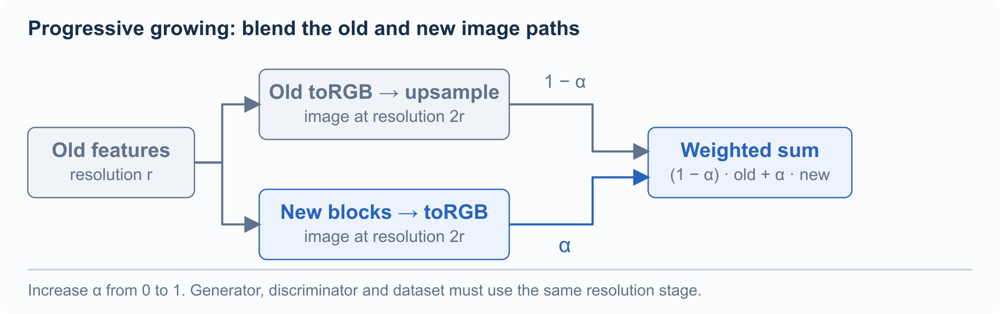

$$I_\alpha=(1-\alpha)\operatorname{Upsample}(I_{\rm old})+\alpha I_{\rm new},\qquad\alpha\in[0,1].$$

At $\alpha=0$, the output follows the old branch; at $\alpha=1$, it follows the new branch. Intermediate values gradually introduce the new resolution. This blends two RGB images, rather than mixing latent styles.

> **Takeaway.** Resolution is a training stage; $\alpha$ controls the transition within a stage. The dataset and both networks must agree on that stage.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [20]:
class AlphaShedulerGeneric:
    def __init__(self):
        pass

    def __call__(self, it):
        raise NotImplementedError()


class ConstantAlphaSheduler(AlphaShedulerGeneric):
    def __init__(self, alpha=1.):
        super().__init__()
        self.alpha = alpha

    def __call__(self, it):
        return self.alpha

class LinearProgressiveAlphaSheduler(AlphaShedulerGeneric):
    def __init__(self, n_growing):
        super().__init__()
        assert n_growing >= 1
        self.n_growing = n_growing

    def __call__(self, it):
        return min(float(it)/self.n_growing, 1.)

## 9. Training

### 9.1  Set up generator and discriminator

In [21]:
z_dim = 128
out_chan = 3

SG_generator = MicroStyleGANGenerator(
    z_dim=z_dim, 
    map_hidden_dim=256,
    w_dim=64,
    in_chan=64,
    out_chan=out_chan, 
    kernel_size=3, 
    hidden_chan=32
)#.cuda()

SG_discriminator = Discriminator(
    in_chan=64,
    out_chan=out_chan, 
    kernel_size=3, 
    hidden_chan=32
)#.cuda()

### 9.2 Set up parameters

In [22]:
BATCH_SIZE = 1024
CRITIC_STEPS = 1
CRITIC_LR=1e-3
GEN_LR=1e-3
GP_WEIGHT = 1.

VARY_PROGRESSIVE_PARAMS = {
    0: {
        'N_EPOCHS': 200,
        'ALPHA_SCHEDULER': ConstantAlphaSheduler(1.),
        'SAVE_STEPS': 200},
    1: {
        'N_EPOCHS': 200,
        'ALPHA_SCHEDULER': LinearProgressiveAlphaSheduler(6000),
        'SAVE_STEPS': 200},
    2: {
        'N_EPOCHS': 300,
        'ALPHA_SCHEDULER': LinearProgressiveAlphaSheduler(6000),
        'SAVE_STEPS': 300},
    3: {
        'N_EPOCHS': 600,
        'ALPHA_SCHEDULER': LinearProgressiveAlphaSheduler(6000),
        'SAVE_STEPS': 200}
}

SM = StatsManager('D_loss', 'G_loss', 'GP', 'alpha', 'step')
IM = ImagesManager()

step2res = {
    0: 4,
    1: 8,
    2: 16,
    3: 32
}

### 9.3 Training the model

Epoch 0


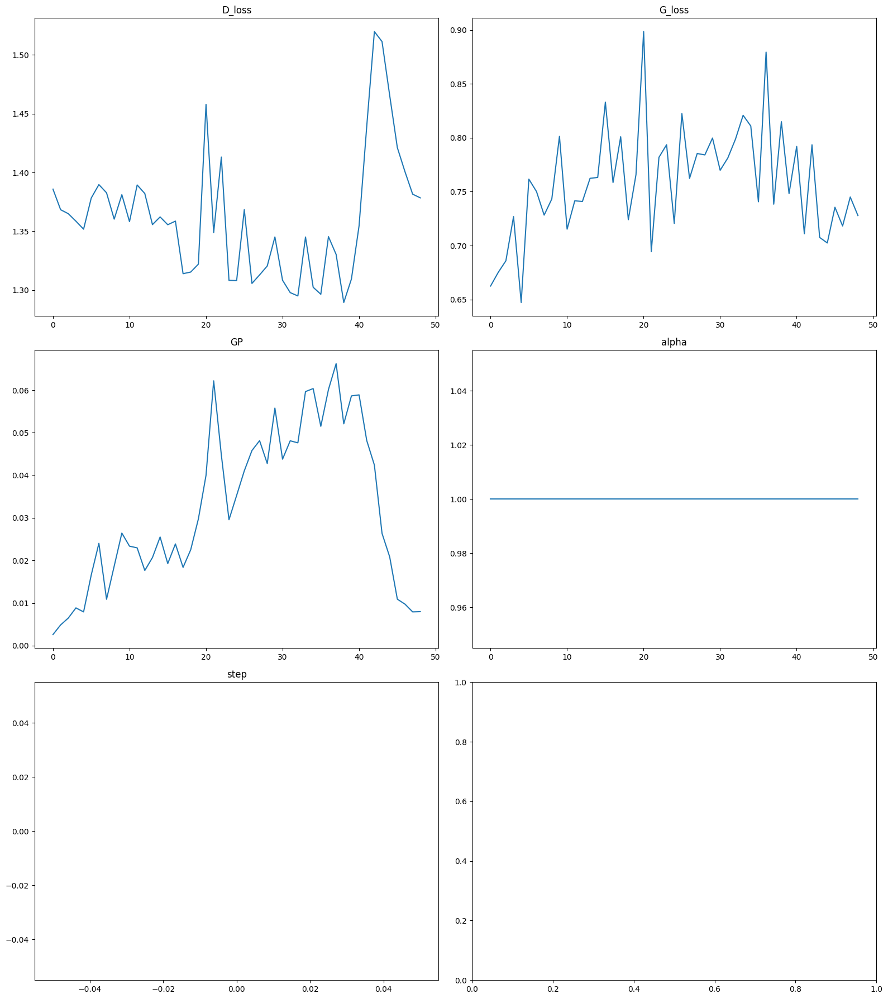

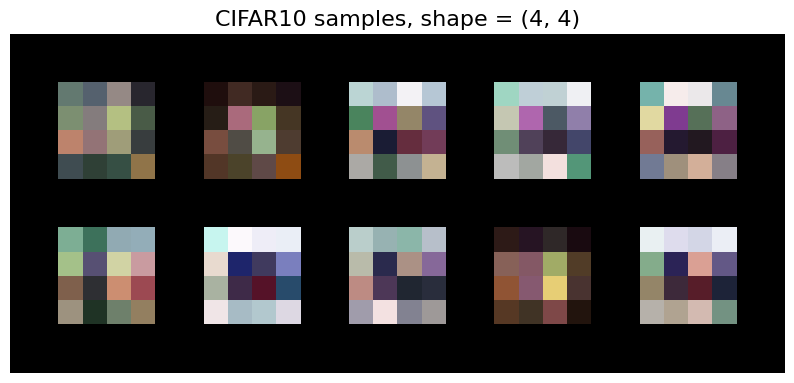

KeyboardInterrupt: 

In [23]:
# complete training

for STEP in [0, 1, 2, 3]:
    
    # create dataloder
    train_dataset.resolution = step2res[STEP]
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    # launch training
    train_GAN_R1(
        SG_generator, 
        SG_discriminator,
        STEP,
        VARY_PROGRESSIVE_PARAMS[STEP]['ALPHA_SCHEDULER'],
        train_loader,
        critic_steps=CRITIC_STEPS, 
        batch_size=BATCH_SIZE, 
        n_epochs=VARY_PROGRESSIVE_PARAMS[STEP]['N_EPOCHS'],
        gen_lr=GEN_LR,
        critic_lr=CRITIC_LR,
        SM=SM,
        IM=IM,
        gp_weight=GP_WEIGHT,
        use_cuda=False,
        visualize_steps = 20,
        save_steps=VARY_PROGRESSIVE_PARAMS[STEP]['SAVE_STEPS']
    )

## 10. Visualization and discussions

### Architecture recap before inspecting samples

| Component | Role | What can change across samples? |
|:---|:---|:---|
| Learned $4\times4$ constant | Shared starting features | Its value is shared once trained |
| Mapping and AdaIN | Style-dependent channel statistics | The style vector $w$ |
| Noise injection | Spatial variation | Each layer's sampled noise |
| Progressive growing | Introduces higher resolutions during training | The stage and its fade-in coefficient |

> **Takeaway.** First inspect image quality and diversity. Then change one control at a time: style, spatial noise, truncation or the set of layers receiving a style.

Let's look at the samples of the trained StyleGAN

In [4]:
import pickle

class CourseCheckpointUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module in {'seminar7_utils', 'seminar10_utils'} and name == 'StatsManager':
            return StatsManager
        return super().find_class(module, name)

# Saved image history from the previous course run.
with open(SEMINAR_DIR / 'checkpoints_gan_r1/im_manager.pkl', 'rb') as filehandler:
    IM = CourseCheckpointUnpickler(filehandler).load()


AttributeError: Can't get attribute 'ImagesManager' on <module '__main__'>

In [7]:
# StatsManager from the complete training
with open(SEMINAR_DIR / 'checkpoints_gan_r1/stats_manager.pkl', 'rb') as filehandler:
     SM = CourseCheckpointUnpickler(filehandler).load()

In [8]:
FULL_DEVICE = 'cpu'

In [9]:
checkpoint = torch.load(SEMINAR_DIR / 'checkpoints_gan_r1/gan_r1_loss_step_3_critic_lr_0.00100_gen_lr_0.00100_critic_steps_1_gp_1.0_FINAL.pth', map_location=FULL_DEVICE)
SG_generator.load_state_dict(checkpoint['generator'])

NameError: name 'torch' is not defined

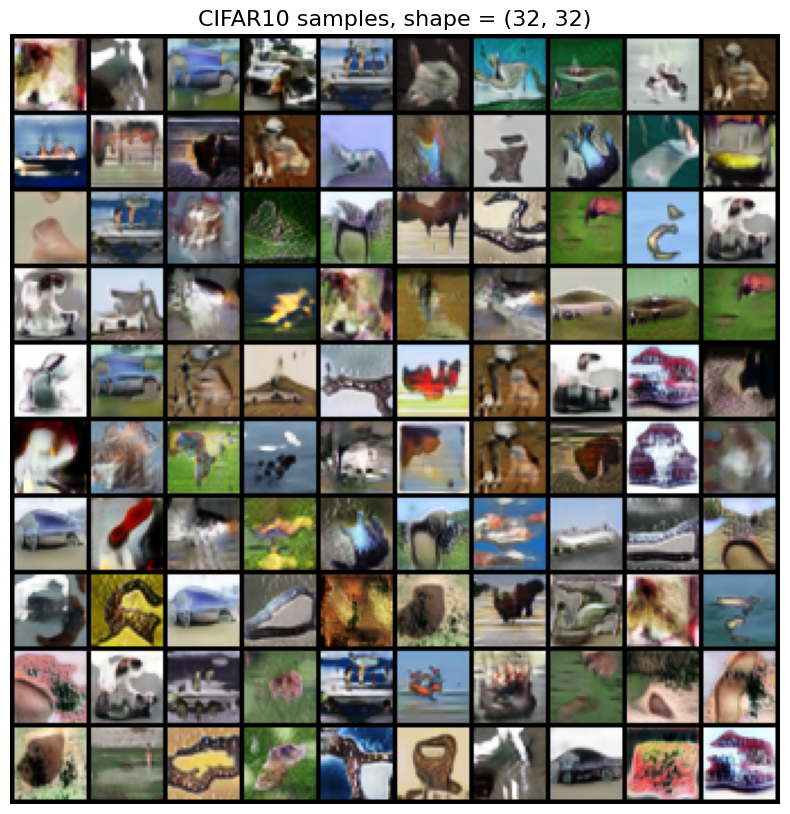

In [ ]:
batch = rawim2im(SG_generator.sample(100, step=3).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(10, 10), nrow=10)

Let's look at the train loss plots

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
SM.draw(axes)
plt.tight_layout()
plt.show(); plt.close(fig)

NameError: name 'plt' is not defined

Let's look at samples during the training

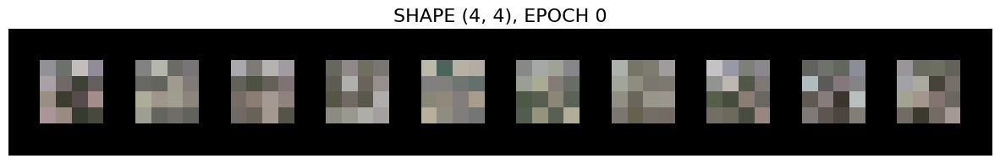

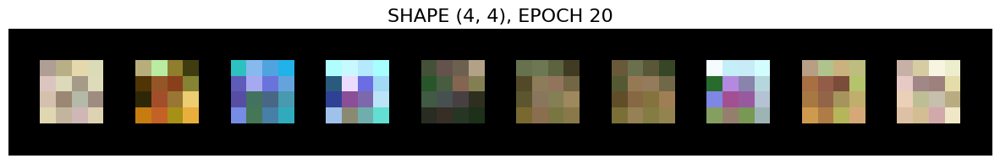

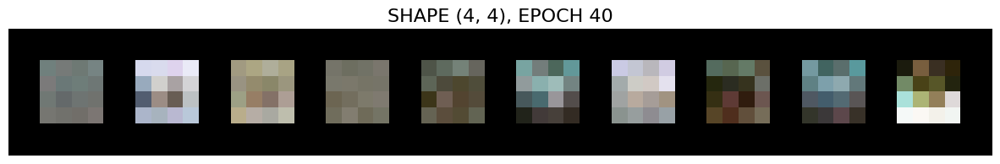

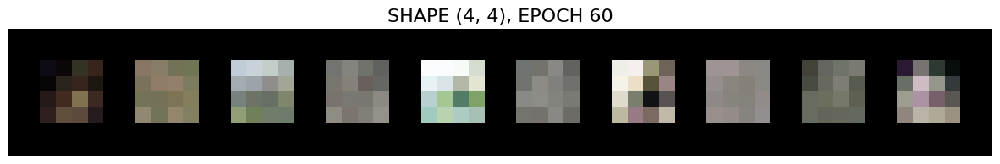

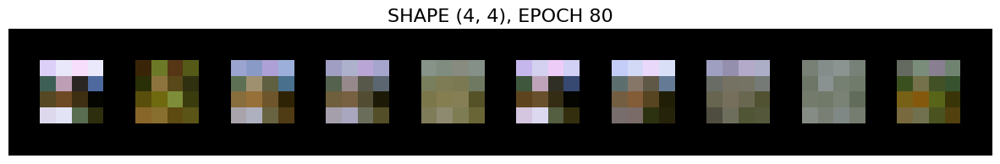

...

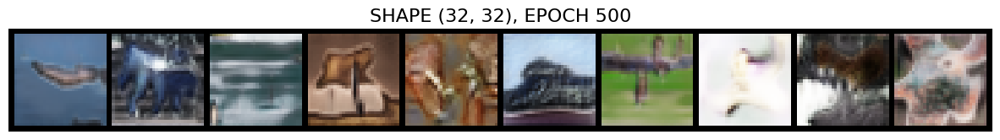

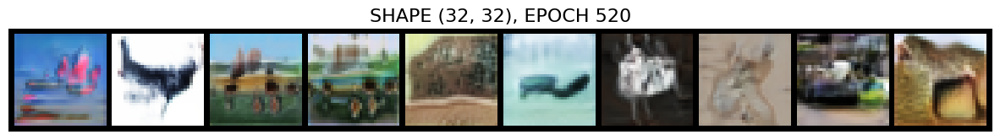

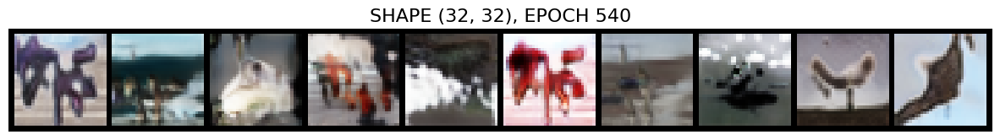

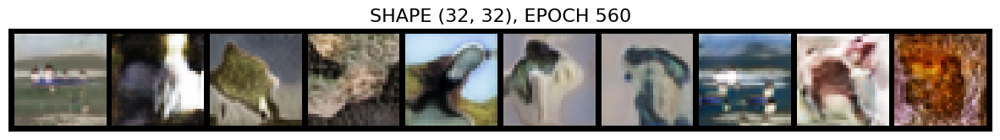

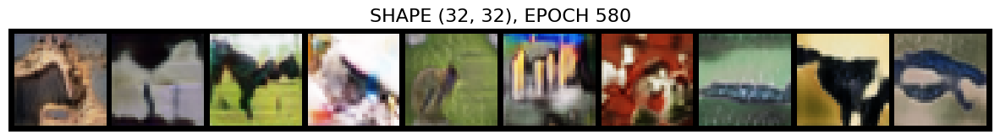

In [ ]:
for res in IM.get_resolutions():
    for epoch in IM.get_epochs(res):
        batch = IM.get_images(res, epoch)[0]
        show_samples(batch, 'SHAPE ({0}, {0}), EPOCH {1}'.format(res, epoch), figsize=(15, 15), nrow=10)

### Truncation toward the empirical mean style

Estimate the mean in $W$ using mapped prior samples:

$$\bar w\approx\frac1N\sum_{i=1}^N f(z_i),\qquad z_i\sim p(z).$$

The cell below uses $N=10\,000$. The next image grid sets `w_weight=0`, so all samples use $w_\psi=\bar w$.

> **Takeaway.** Similar images at $\psi=0$ are the intended consequence of removing style variation. Remaining differences can come from spatial noise. A negative `w_weight`, used in a later experiment, reflects styles across the mean; it does not contract them toward the mean.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [ ]:
with torch.no_grad():
    noise = SG_generator._sample_prior(10000)
    w = SG_generator.map(noise)
    w_mean = w.mean(dim=0)

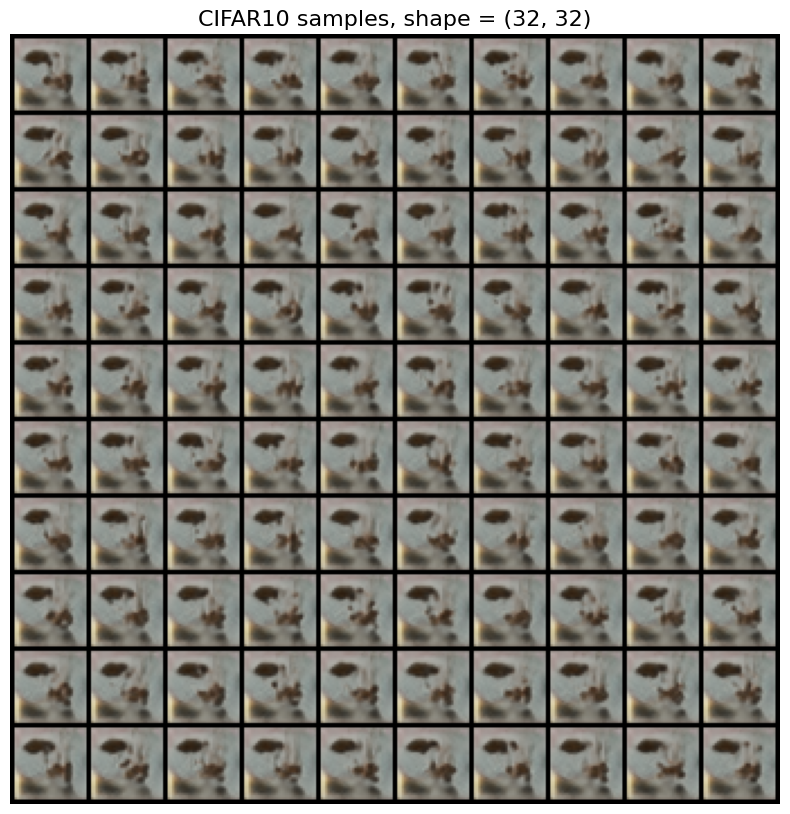

In [ ]:
batch = rawim2im(SG_generator.sample(100, step=3, w_mean=w_mean, w_weight=0).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(10, 10), nrow=10)

## 11. Alternative versions of the model

### 11.1 GAN with $R_1$ (more training iterations)

In [ ]:
SG_generator_alt = MicroStyleGANGenerator(
    z_dim=z_dim, 
    map_hidden_dim=256,
    w_dim=64,
    in_chan=64,
    out_chan=out_chan, 
    kernel_size=3, 
    hidden_chan=32
)#.cuda()

In [ ]:
checkpoint = torch.load(SEMINAR_DIR / 'checkpoints_old/gan_loss_step_3_critic_lr_0.00100_gen_lr_0.00100_critic_steps_1_gp_1.0_v2_FINAL.pth', map_location=FULL_DEVICE)
SG_generator_alt.load_state_dict(checkpoint['generator'])

<All keys matched successfully>

Computation of `w_mean`

In [ ]:
with torch.no_grad():
    noise = SG_generator_alt._sample_prior(10000)
    w = SG_generator_alt.map(noise)
    w_mean_alt = w.mean(dim=0)

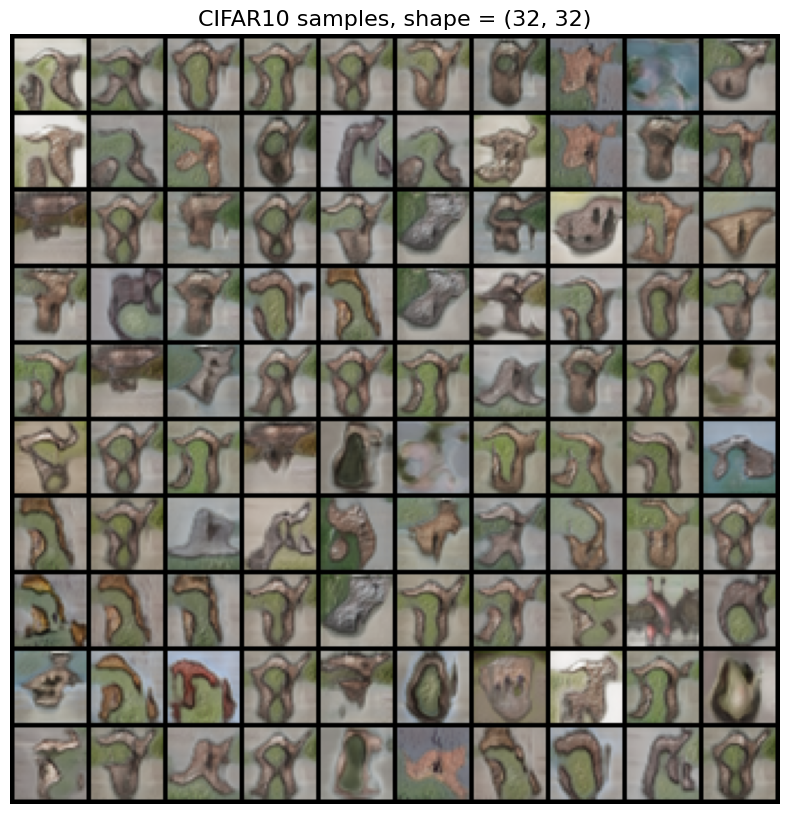

In [ ]:
batch = rawim2im(SG_generator_alt.sample(100, step=3, w_mean=w_mean_alt, w_weight=0.2).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(10, 10), nrow=10)

### 11.2 WGAN-GP

In [ ]:
SG_generator_wgan = MicroStyleGANGenerator(
    z_dim=z_dim, 
    map_hidden_dim=256,
    w_dim=64,
    in_chan=64,
    out_chan=out_chan, 
    kernel_size=3, 
    hidden_chan=32
)#.cuda()

In [ ]:
checkpoint = torch.load(
    SEMINAR_DIR / 'checkpoints_old/wgan_tanh_loss_step_3_alpha_linear_6000_critic_lr_0.00070_gen_lr_0.00070_critic_steps_5_gp_1.0_FINAL.pth', map_location=FULL_DEVICE)
SG_generator_wgan.load_state_dict(checkpoint['generator'])

<All keys matched successfully>

Computation of `w_mean`

In [ ]:
with torch.no_grad():
    noise = SG_generator_wgan._sample_prior(10000)
    w = SG_generator_wgan.map(noise)
    w_mean_wgangp = w.mean(dim=0)

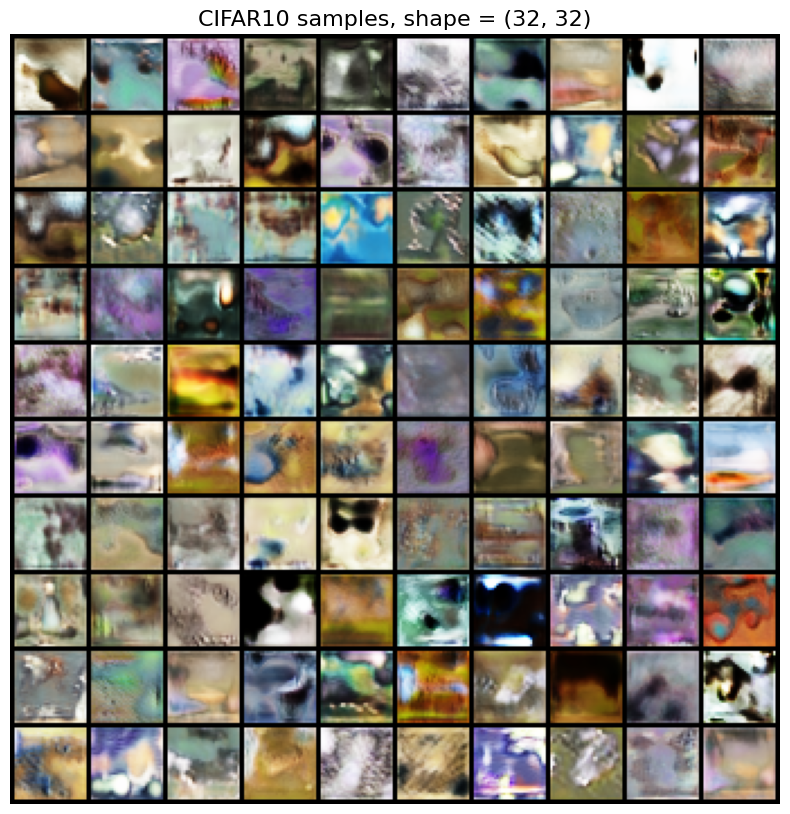

In [ ]:
batch = rawim2im(SG_generator_wgan.sample(100, step=3, w_mean=w_mean_wgangp, w_weight=-1).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(10, 10), nrow=10)

## 12. StyleGAN features

### 12.1 Style variation

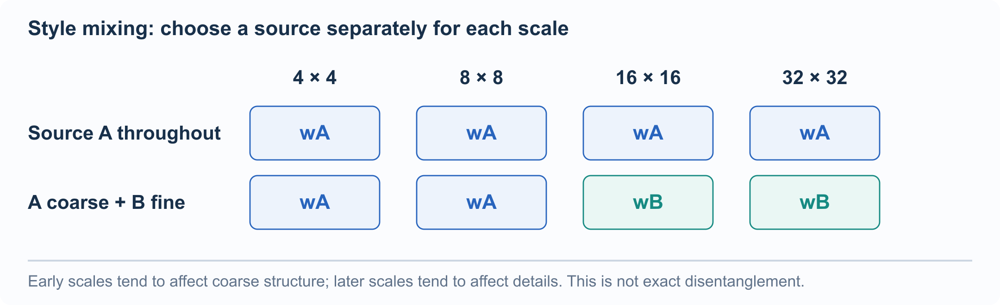

`generate_styled` accepts one style for each of the four resolution stages: $4,8,16,32$. Inside a stage, both styled blocks receive that same style.

$$[w_A,w_A,w_B,w_B]\quad\longrightarrow\quad\text{coarse scales from A, fine scales from B}.$$

The setup below constructs two experiments:

| Input | Fixed across the grid | Varying across the grid |
|:---|:---|:---|
| `ws_map[0]` | First two stages: coarse | Last two stages: fine |
| `ws_map[1]` | Last two stages: fine | First two stages: coarse |

> **Takeaway.** Layer position gives a useful degree of control over scale, not an exact semantic switch. These are post-training experiments; the training loop above does not implement style-mixing regularization.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [ ]:
def generate_styled(model, ws):
    assert len(ws) == 4
    with torch.no_grad():
        x = model.starting_constant
        for conv, w in zip(model.progression, ws):
            x = conv(x, w)
        return model.to_rgb[-1](x)

In [ ]:
#reset_seed()
with torch.no_grad():
    noise = SG_generator_alt._sample_prior(200)
    ws_basic = SG_generator_alt.map(noise).view(2, 100, -1)
    ws_map = {}
    for i in range(2):
        ws = ws_basic.clone()
        ws[i] = ws[i][0].unsqueeze(0).repeat_interleave(ws_basic.size(1), 0)
        ws_map[i] = [ws[0], ws[0], ws[1], ws[1]]

### Vary coarse styles, fix fine styles

`ws_map[1]`: compare changes in global structure while the styles at the last two stages stay fixed.

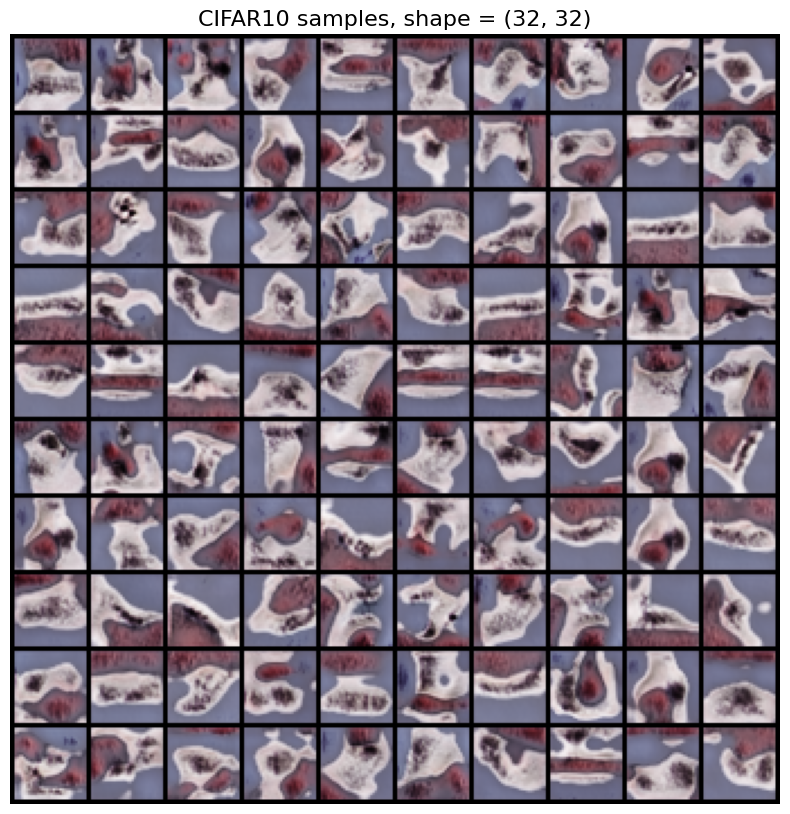

In [ ]:
batch = rawim2im(generate_styled(SG_generator_alt, ws_map[1]).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(10, 10), nrow=10)

### Fix coarse styles, vary fine styles

`ws_map[0]`: compare changes at later scales while the styles at the first two stages stay fixed.

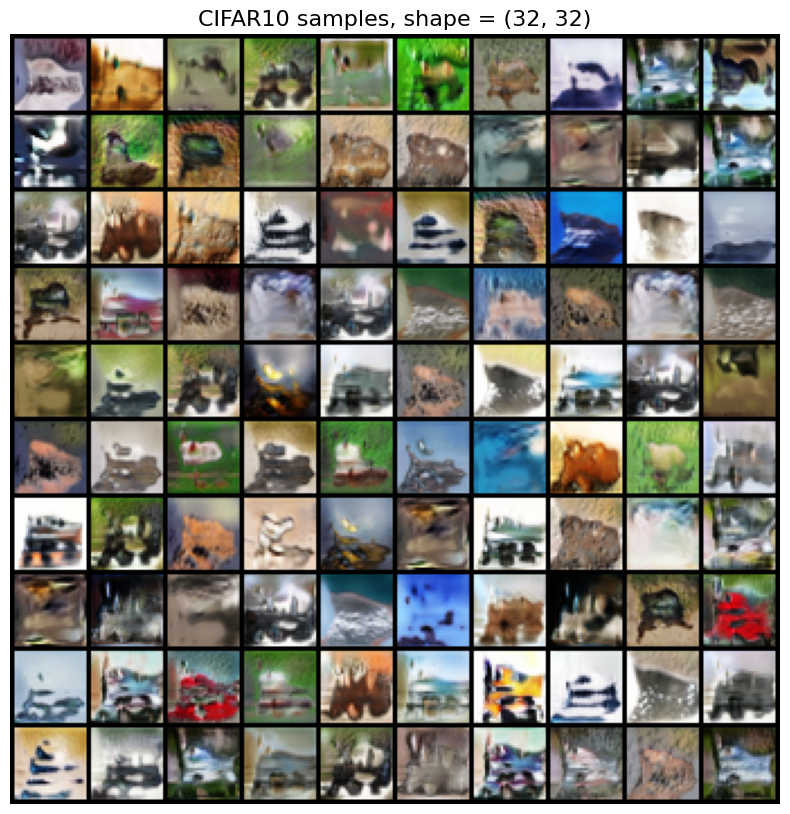

In [ ]:
batch = rawim2im(generate_styled(SG_generator_alt, ws_map[0]).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(10, 10), nrow=10)

### 12.2 Playing with interpolation

For two mapped styles, interpolate along a line in $W$:

$$w(t)=(1-t)w_A+t\,w_B,\qquad t\in[0,1].$$

Feed $w(t)$ to either the first two stages or the last two stages while keeping the other styles fixed. The endpoint styles are unchanged; intermediate points blend their coordinates.

> **Takeaway.** A line in $W$ is generally different from mapping a line in $Z$: $f((1-t)z_A+tz_B)\ne(1-t)f(z_A)+tf(z_B)$. The later pretrained playground interpolates in $Z$. Spatial noise can also contribute to differences between frames.

<small>Source: [Karras et al., A Style-Based Generator Architecture for GANs (2019)](https://arxiv.org/abs/1812.04948)</small>

In [ ]:
def tsr_linspace(a, b, num):
    res = torch.zeros_like(a).unsqueeze(0).repeat_interleave(num + 1, 0)
    for i in range(num + 1):
        res[i] = a + i * (b - a)/num
    return res

#reset_seed()
with torch.no_grad():
    noise = SG_generator_alt._sample_prior(4 * 20)
    ws_borders = SG_generator_alt.map(noise).view(20, 2, 2, -1)[19]
    ws_basic_linspace = tsr_linspace(ws_borders[0], ws_borders[1], 19).transpose(0, 1) # (2, 20, w_shape)

    ws_map = {}
    for i in range(2):
        ws = ws_basic_linspace.clone()
        ws[i] = ws[i][-1].unsqueeze(0).repeat_interleave(ws_basic_linspace.size(1), 0)
        ws_map[i] = [ws[0], ws[0], ws[1], ws[1]]

### Interpolate coarse styles, fix fine styles

`ws_map[1]`: change the first two stages along the interpolation path.

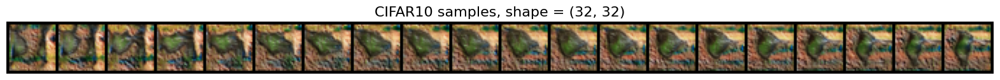

In [ ]:
batch = rawim2im(generate_styled(SG_generator_alt, ws_map[1]).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(20, 20), nrow=20)

### Fix coarse styles, interpolate fine styles

`ws_map[0]`: change the last two stages along the interpolation path.

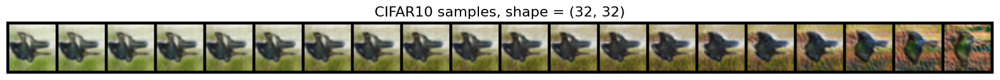

In [ ]:
batch = rawim2im(generate_styled(SG_generator_alt, ws_map[0]).detach().cpu().numpy())
show_samples(batch, 'CIFAR10 samples, shape = ({0}, {0})'.format(32), figsize=(20, 20), nrow=20)

### StyleGAN Playground

In [2]:
import subprocess

STYLEGAN2_DIR = SEMINAR_DIR / 'stylegan2-ada-pytorch'
if not STYLEGAN2_DIR.is_dir():
    subprocess.run([
        'git', 'clone', 'https://github.com/NVlabs/stylegan2-ada-pytorch',
        str(STYLEGAN2_DIR),
    ], check=True)


In [3]:
import sys
sys.path.insert(0, str(STYLEGAN2_DIR))


In [4]:
import os
import numpy as np

import torch
import torchvision.transforms as transforms

from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [5]:
import dnnlib
import legacy

In [6]:
# Seed everything
torch.manual_seed(42)
np.random.seed(42)

In [7]:
# Function to load a pretrained StyleGAN2 model
def load_stylegan_model(model_path):
    """
    Loads a pretrained StyleGAN2 model
    
    Args:
        model_path: path to the model file (.pkl)
    
    Returns:
        StyleGAN2 model with interfaces for image generation
    """
    print(f"Loading model from {model_path}")
    
    # Determine the computation device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Load the network
    with dnnlib.util.open_url(model_path) as f:
        G = legacy.load_network_pkl(f)['G_ema'].to(device)  # Pretrained generator
    
    return G, device

In [8]:
# Function to generate a face from a random latent vector
def generate_random_face(G, device, seed=None, truncation_psi=0.7):
    """
    Generates a random face using StyleGAN2
    
    Args:
        G: StyleGAN2 generator model
        device: computational device (cpu/cuda)
        seed: seed for random number generator
        truncation_psi: truncation parameter to control variability
        
    Returns:
        Generated face image and latent vector
    """
    if seed is not None:
        torch.manual_seed(int(seed))
    
    # Latent vector size for StyleGAN2
    z_dim = G.z_dim
    
    # Create random latent vector
    z = torch.randn([1, z_dim], device=device)
    
    # Generate image
    with torch.no_grad():
        img = G(z, None, truncation_psi=truncation_psi, noise_mode='const',
                    force_fp32=(device.type != 'cuda'))
    
    # Convert format for display
    img = (img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
    img = img[0].cpu().numpy()
    
    return img, z

In [9]:
# Function to interpolate between two latent vectors
def interpolate_latent_vectors(z1, z2, num_steps=10):
    """
    Creates an interpolation between two latent vectors
    
    Args:
        z1: starting latent vector
        z2: ending latent vector
        num_steps: number of interpolation steps
        
    Returns:
        List of interpolated latent vectors
    """
    vectors = []
    for i in range(num_steps):
        # Linear interpolation with parameter t from 0 to 1
        t = i / (num_steps - 1)
        z_interp = (1 - t) * z1 + t * z2
        vectors.append(z_interp)
    return vectors

# Function to create a set of interpolated images
def generate_interpolation_frames(G, z1, z2, device, num_steps=10, truncation_psi=0.7):
    """
    Generates a series of images interpolated between two latent vectors
    
    Args:
        G: StyleGAN2 generator model
        z1: starting latent vector
        z2: ending latent vector
        device: computation device (cpu/cuda)
        num_steps: number of interpolation steps
        truncation_psi: truncation parameter to control variability
        
    Returns:
        List of images representing the interpolation
    """
    interpolated_z = interpolate_latent_vectors(z1, z2, num_steps)
    images = []
    
    with torch.no_grad():
        for z in tqdm(interpolated_z):
            # Generate image
            img = G(z, None, truncation_psi=truncation_psi, noise_mode='const',
                    force_fp32=(device.type != 'cuda'))
            
            # Convert format for display
            img = (img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
            img = img[0].cpu().numpy()
            
            images.append(img)
        
    return images

In [10]:
# Display a selected set of interpolation frames with their actual t values.
def visualize_interpolation(images, title="StyleGAN2 — interpolation in Z", t_values=None):
    n = len(images)
    if t_values is None:
        t_values = np.linspace(0, 1, n)
    fig, axs = plt.subplots(1, n, figsize=(n * 4, 4), squeeze=False)
    for ax, img, t in zip(axs[0], images, t_values):
        ax.imshow(img)
        ax.set_title(f"t = {t:.2f}")
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


In [11]:
# Create a compact animation and embed its bytes in the notebook output.
def create_interpolation_animation(images, output_path="interpolation.gif", duration=600, endpoint_pause=1500):
    from PIL import ImageDraw
    from IPython.display import Image as DisplayImage, display

    frames = []
    for i, image in enumerate(images):
        frame = Image.new('RGB', (512, 544), 'white')
        frame.paste(Image.fromarray(image).resize((512, 512), Image.Resampling.LANCZOS), (0, 32))
        ImageDraw.Draw(frame).text((12, 10), f"Interpolation in Z | t = {i / (len(images) - 1):.2f}", fill='black')
        frames.append(frame)
    # Ping-pong playback makes the return to the first endpoint smooth.
    playback = frames + frames[-2:0:-1]
    durations = [duration] * len(playback)
    durations[0] = durations[len(frames) - 1] = endpoint_pause
    playback[0].save(output_path, save_all=True, append_images=playback[1:],
                     duration=durations, loop=0, optimize=False)
    display(DisplayImage(filename=str(output_path)))


In [12]:
# Function to save images
def save_images(images, output_dir):
    """
    Saves images to the specified directory
    
    Args:
        images: list of images to save
        output_dir: directory for saving
    """
    os.makedirs(output_dir, exist_ok=True)
    
    for i, img in enumerate(images):
        pil_img = Image.fromarray(img)
        pil_img.save(os.path.join(output_dir, f"interp_{i:02d}.png"))

In [13]:
local_ffhq = SEMINAR_DIR / 'checkpoints_stylegan2' / 'ffhq.pkl'
model_path = (str(local_ffhq) if local_ffhq.is_file() else
              "https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/ffhq.pkl")
output_dir = "output"
male_seed = "43"
female_seed = "42"

In [14]:
# Сreate the dir
os.makedirs(output_dir, exist_ok=True)

In [15]:
%%time

# Load the model
G, device = load_stylegan_model(model_path)

Loading model from /Users/matvey/matveymor/2026-DGM-MIPT-YSDA-course/seminars/seminar5/checkpoints_stylegan2/ffhq.pkl
Using device: cpu


CPU times: user 278 ms, sys: 184 ms, total: 462 ms
Wall time: 566 ms


In [16]:
print(G)

Generator(
  (synthesis): SynthesisNetwork(
    (b4): SynthesisBlock(
      (conv1): SynthesisLayer(
        (affine): FullyConnectedLayer()
      )
      (torgb): ToRGBLayer(
        (affine): FullyConnectedLayer()
      )
    )
    (b8): SynthesisBlock(
      (conv0): SynthesisLayer(
        (affine): FullyConnectedLayer()
      )
      (conv1): SynthesisLayer(
        (affine): FullyConnectedLayer()
      )
      (torgb): ToRGBLayer(
        (affine): FullyConnectedLayer()
      )
    )
    (b16): SynthesisBlock(
      (conv0): SynthesisLayer(
        (affine): FullyConnectedLayer()
      )
      (conv1): SynthesisLayer(
        (affine): FullyConnectedLayer()
      )
      (torgb): ToRGBLayer(
        (affine): FullyConnectedLayer()
      )
    )
    (b32): SynthesisBlock(
      (conv0): SynthesisLayer(
        (affine): FullyConnectedLayer()
      )
      (conv1): SynthesisLayer(
        (affine): FullyConnectedLayer()
      )
      (torgb): ToRGBLayer(
        (affine): FullyConn

In [17]:
%%time

# Generating the male face
male_img, male_z = generate_random_face(G, device, seed=male_seed)

CPU times: user 3.84 s, sys: 1.98 s, total: 5.83 s
Wall time: 1.73 s


In [18]:
%%time

# Generating the female face
female_img, female_z = generate_random_face(G, device, seed=female_seed)

CPU times: user 3.73 s, sys: 1.92 s, total: 5.65 s
Wall time: 1.72 s


In [19]:
# Saving the images
Image.fromarray(male_img).save(os.path.join(output_dir, "male.png"))
Image.fromarray(female_img).save(os.path.join(output_dir, "female.png"))

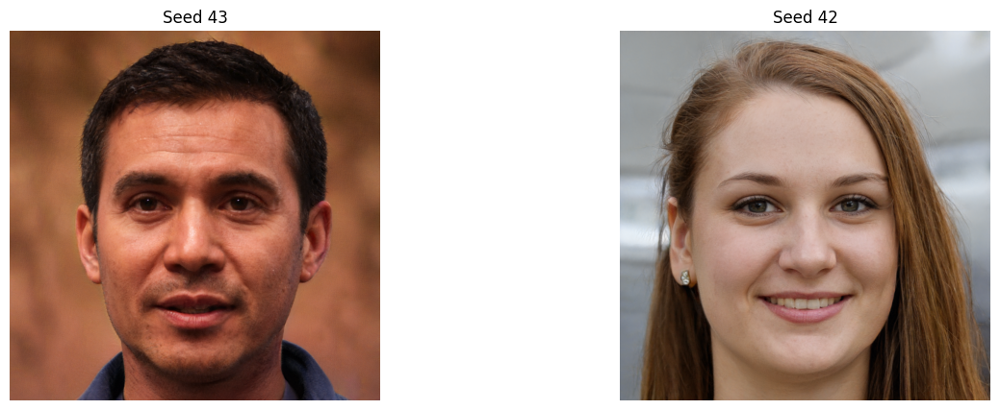

In [20]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.imshow(male_img)
plt.title(f"Seed {male_seed}")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(female_img)
plt.title(f"Seed {female_seed}")
plt.axis('off')
plt.show()

In [21]:
%%time

# Interpolating images
num_steps = 11  # Includes the exact midpoint t = 0.5.
interpolated_images = generate_interpolation_frames(G, male_z, female_z, device, num_steps)

  0%|          | 0/11 [00:00<?, ?it/s]

  9%|▉         | 1/11 [00:01<00:17,  1.73s/it]

 18%|█▊        | 2/11 [00:02<00:12,  1.42s/it]

 27%|██▋       | 3/11 [00:04<00:10,  1.32s/it]

 36%|███▋      | 4/11 [00:05<00:08,  1.26s/it]

 45%|████▌     | 5/11 [00:06<00:07,  1.22s/it]

 55%|█████▍    | 6/11 [00:07<00:06,  1.33s/it]

 64%|██████▎   | 7/11 [00:09<00:05,  1.29s/it]

 73%|███████▎  | 8/11 [00:10<00:03,  1.25s/it]

 82%|████████▏ | 9/11 [00:11<00:02,  1.23s/it]

 91%|█████████ | 10/11 [00:12<00:01,  1.25s/it]

100%|██████████| 11/11 [00:14<00:00,  1.25s/it]

100%|██████████| 11/11 [00:14<00:00,  1.28s/it]

CPU times: user 39.1 s, sys: 15.4 s, total: 54.4 s
Wall time: 14.1 s


In [22]:
# Saving all interpolation steps
save_images(interpolated_images, output_dir)

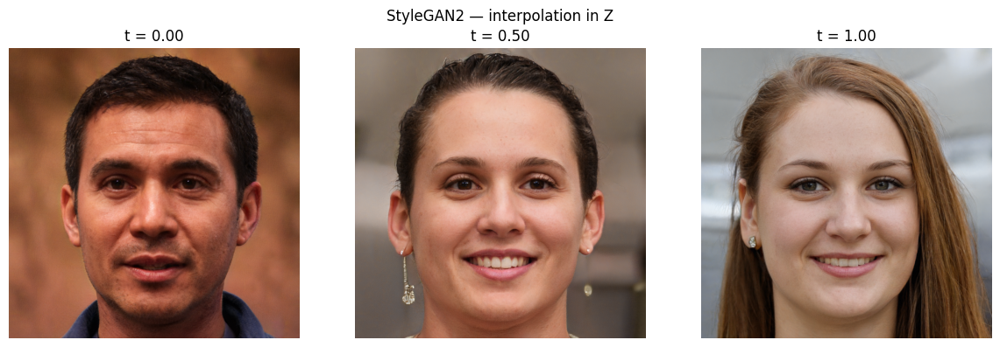

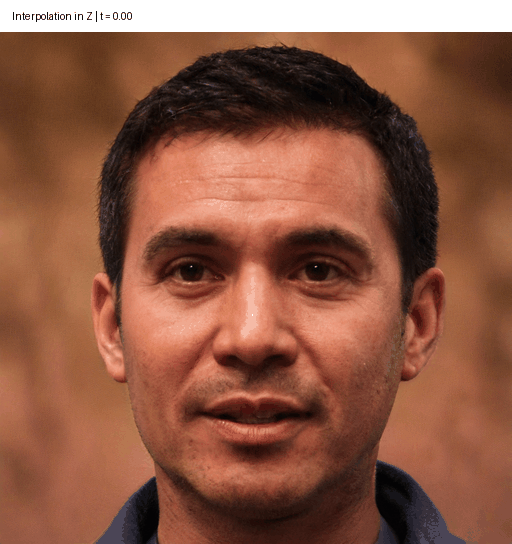

In [23]:
# Static endpoints and midpoint remain visible without running any code.
selected_steps = [0, num_steps // 2, num_steps - 1]
visualize_interpolation(
    [interpolated_images[i] for i in selected_steps],
    t_values=[i / (num_steps - 1) for i in selected_steps],
)

# The animation is embedded in this output, not linked to an external file.
create_interpolation_animation(interpolated_images,
                               os.path.join(output_dir, "interpolation.gif"))


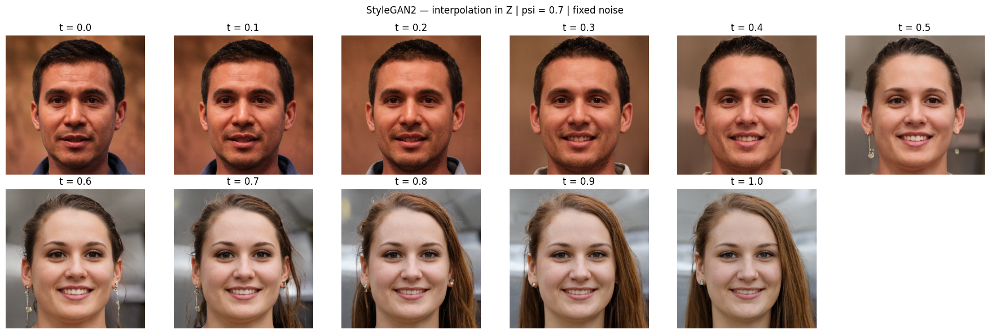

In [24]:
# A static contact sheet of every generated interpolation step.
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for i, ax in enumerate(axes.flat):
    ax.axis('off')
    if i < len(interpolated_images):
        ax.imshow(interpolated_images[i])
        ax.set_title(f"t = {i / (num_steps - 1):.1f}")
fig.suptitle("StyleGAN2 — interpolation in Z | psi = 0.7 | fixed noise")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "comparison.png"), dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
%%time

# Generating the child face
child_seed = 0
child_img, child_z = generate_random_face(G, device, seed=child_seed)


plt.imshow(child_img)
plt.title("child")
plt.axis('off')
plt.show()

In [ ]:
def generate_child_with_future_appearance(G, child_seed=0, adult_seed=42, output_dir="child_future"):
    """
    Generates a child from noise and predicts their future appearance
    using style mixing
    
    Args:
        G: StyleGAN2 generator model
        child_seed: seed for generating child's face
        adult_seed: seed for generating adult face (age feature donor)
        output_dir: directory to save results
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    os.makedirs(output_dir, exist_ok=True)
    
    # Generate child's face
    torch.manual_seed(child_seed)
    z_child = torch.randn([1, G.z_dim], device=device)
    
    # Generate adult face (age feature donor)
    torch.manual_seed(adult_seed)
    z_adult = torch.randn([1, G.z_dim], device=device)
    
    # Get W-vectors
    with torch.no_grad():
        w_child = G.mapping(z_child, None, truncation_psi=0.7)
        w_adult = G.mapping(z_adult, None, truncation_psi=0.7)
        
        # Generate original images
        img_child = G.synthesis(w_child, noise_mode='const')
        img_adult = G.synthesis(w_adult, noise_mode='const')
        
        # Convert to displayable format
        img_child = (img_child.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)[0].cpu().numpy()
        img_adult = (img_adult.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)[0].cpu().numpy()
    
    # Save original images
    Image.fromarray(img_child).save(os.path.join(output_dir, "child_original.png"))
    Image.fromarray(img_adult).save(os.path.join(output_dir, "adult_donor.png"))
    
    # Create prediction variants with different degrees of style mixing
    predictions = []
    titles = []
    
    # Create several variants by changing the style mixing boundary
    style_boundaries = [
        (0, 4),    # Keep only the earliest child styles (face shape)
        (0, 8),    # Keep more child styles
        (0, 12),   # Keep even more child styles
    ]
    
    for start_idx, end_idx in tqdm(style_boundaries):
        # Create mixed W-vector
        w_mixed = w_child.clone()
        
        # Replace styles after certain layer with adult styles
        w_mixed[:, end_idx:, :] = w_adult[:, end_idx:, :]
        
        # Generate prediction image
        with torch.no_grad():
            img_prediction = G.synthesis(w_mixed, noise_mode='const')
            img_prediction = (img_prediction.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)[0].cpu().numpy()
        
        # Save the result
        Image.fromarray(img_prediction).save(
            os.path.join(output_dir, f"future_prediction_layers_{end_idx}.png")
        )
        
        predictions.append(img_prediction)
        titles.append(f"Prediction (styles 0-{end_idx})")
    
    # Visualize results
    plt.figure(figsize=((len(predictions) + 2) * 4, 5))
    
    # Original child
    plt.subplot(1, len(predictions) + 2, 1)
    plt.imshow(img_child)
    plt.title("Child")
    plt.axis('off')
    
    # Predictions
    for i, (img, title) in enumerate(zip(predictions, titles)):
        plt.subplot(1, len(predictions) + 2, i + 2)
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    
    # Adult donor
    plt.subplot(1, len(predictions) + 2, len(predictions) + 2)
    plt.imshow(img_adult)
    plt.title("Adult Donor")
    plt.axis('off')
    
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "predictions_comparison.png"))
    plt.show()
    
    return img_child, predictions, img_adult

In [ ]:
img_child, predictions, img_adult = generate_child_with_future_appearance(G, child_seed=0, adult_seed=42, output_dir="child_future")

### Key Differences Between StyleGAN Versions

| Feature | StyleGAN | StyleGAN2 | StyleGAN3 |
|---------|----------|-----------|-----------|
| Main Innovation | Style-based generator with AdaIN | Redesigned normalization with weight demodulation | Alias-free design for rotation equivariance |
| Training Method | Progressive growing | Non-progressive training | Non-progressive with alias-free design |
| Key Issue Fixed | Initial style-based approach | "Droplet" artifacts | "Texture sticking" problem |
| Normalization | AdaIN (Adaptive Instance Normalization) | Weight modulation and demodulation | Weight modulation with filtered sampling |
| Feature Locality | Fixed feature positioning | Improved but with "texture sticking" | Natural feature movement with transformations |
| Latent Space | Z-space and W-space | Z-space, W-space, and W+ space | Z-space, W-space, and W+ space |

### Latent Inversion Playground

https://github.com/yandexdataschool/deep_vision_and_graphics/tree/fall24/week08-gans

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yandexdataschool/deep_vision_and_graphics/blob/fall24/week08-gans/seminar.ipynb#scrollTo=uPMeGKf1cCQA)

## Seminars 4–5 — conclusions

1. **Training signal:** the discriminator or critic teaches the generator through input gradients. Preserve the gradient path on the generator update.
2. **Loss choice:** non-saturating GAN strengthens one derivative factor; WGAN changes the discrepancy being estimated; WGAN-GP regularizes the critic between real and fake data.
3. **Generator structure:** StyleGAN separates a shared constant, a mapped style and spatial noise. AdaIN applies style-dependent channel statistics in the teaching model.
4. **Control:** truncation changes the spread around the mean style; mixing assigns styles to different scales; interpolation traces a path in latent space.
5. **Evidence:** inspect generated samples as well as losses. A convincing interpolation demonstrates a property of the generator, not a prediction of a person's future appearance.

> **Final question.** If we keep $w$ fixed but resample the injected noise, what should remain broadly similar, and what can still change?